In [1]:
import glob
#import TEST_0202
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

In [2]:
#esospec_comp = glob.glob('/Users/mariajesusfloresmoraga/Desktop/IFMR_3/P111/esospec_comp/wds/*/*.csv')
esospec_corr_comp = glob.glob('/Users/mariajesusfloresmoraga/Desktop/IFMR_4/P116/esospec_corr_comp/wds/*/*.csv')

In [3]:
def bad_pixels(nombre, wave, flux, window, std_cut, lim_core=10, plot_bad = False):

    min_periods = np.round(window/2,0)
    min_periods = int(min_periods)

    s_wave = pd.Series(wave)
    s_flux = pd.Series(flux)

    #plt.plot(s_wave, s_flux)
    #plt.title(f'{nombre}')
    #plt.axvline(5750)
    #plt.axvline(5840)
    #plt.show()

    rolling_median = s_flux.rolling(window=window, center=True, min_periods=min_periods).median() #queda en Nan en los bordes
    rolling_std = s_flux.rolling(window=window, center=True, min_periods=min_periods).std() #queda en Nan en los bordes
    
    rolling_std = rolling_std * 0 + np.median(rolling_std)
    
    
    bad_mask = ( s_flux >=  (rolling_median + std_cut*rolling_std) ) | ( s_flux <=  (rolling_median - std_cut*rolling_std) )


    s_wave_corrected = s_wave[~bad_mask]
    s_flux_corrected = s_flux[~bad_mask]

    if plot_bad == True:

        plt.plot(s_wave, rolling_median, c='r', lw=.5, label='Moving average')
        plt.fill_between(s_wave, rolling_median - std_cut*rolling_std, rolling_median + std_cut*rolling_std, color='lightgray')
        plt.scatter(s_wave[bad_mask], s_flux[bad_mask], s=1.5, c='r')
        
        #plt.show()
    
        plt.scatter(s_wave, s_flux, s=.5, c='k')
        plt.scatter(s_wave[bad_mask], s_flux[bad_mask], s=1.5, c='r')#, ymax = max(s_flux), ymin = min(s_flux), lw=0.5, color='r')
        plt.title(f'{nombre}', fontsize=15)
        #plt.xlim(6560, 6566)
        plt.xlabel('Wavelength (A)', fontsize=15)
        plt.ylabel('Relative Flux', fontsize=15)
        plt.legend(fontsize=15)
        #plt.xlim(5600,6700)
        #plt.xlim(4700, 5600)
        #plt.savefig(f'movingAV_{nombre}_Hb.pdf', dpi=300)
        plt.show()
        #plt.close()

    s_wave_final =  s_wave_corrected.tolist()
    s_wave_final = np.array(s_wave_final)
    
    s_flux_final = s_flux_corrected.tolist()
    s_flux_final = np.array(s_flux_final)
    return s_wave_final, s_flux_final

In [4]:
g00 = 4580 - 40
g01 = 4580 + 40
g10 = 5600
g11 = 5850

cleaned_corr_comp/wds/cleaned_corr_spec3119751_20220117T060853894


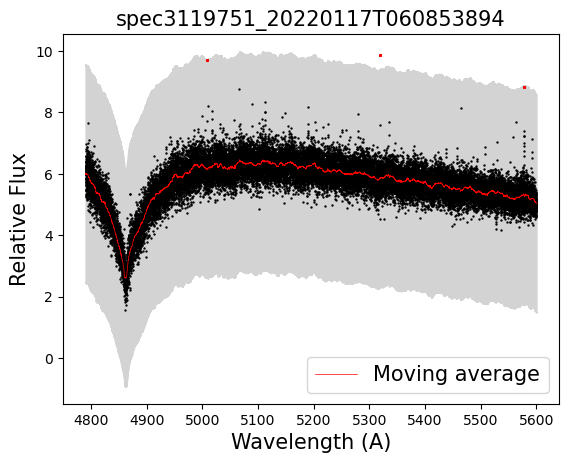

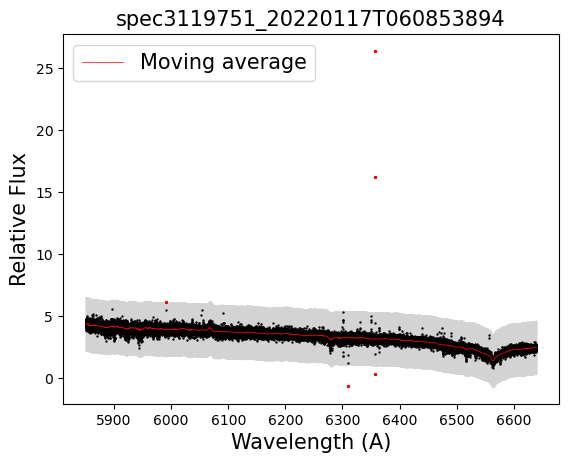

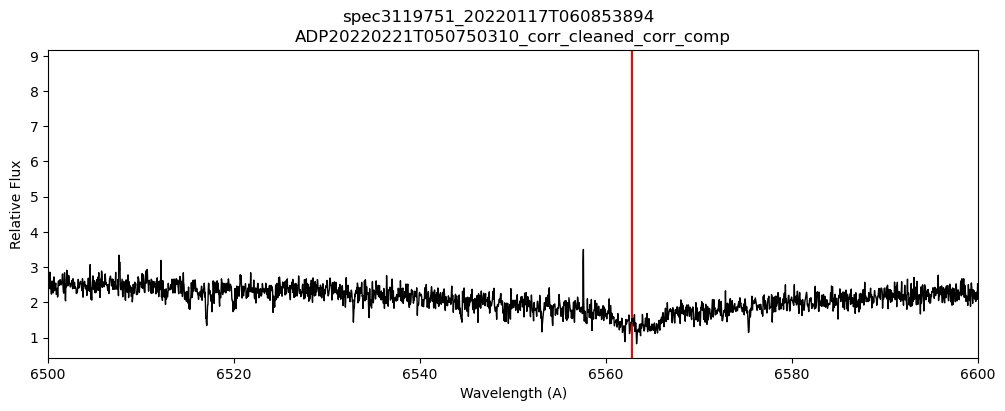

cleaned_corr_comp/wds/cleaned_corr_spec4498469_20251226T032002684


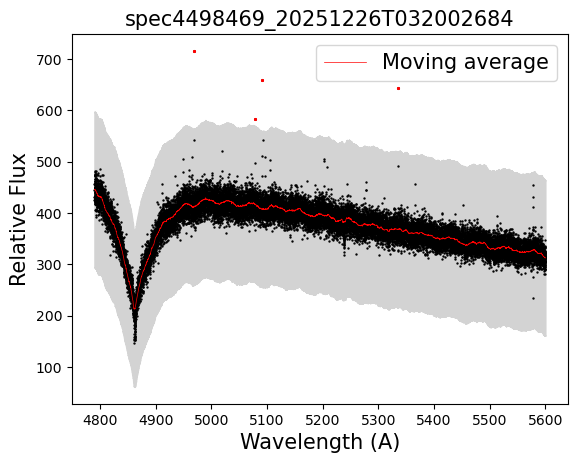

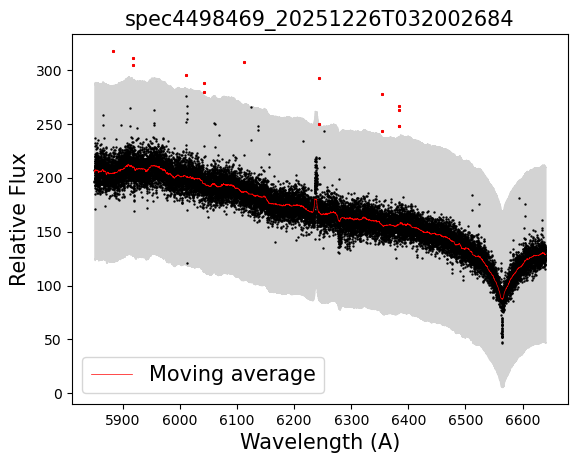

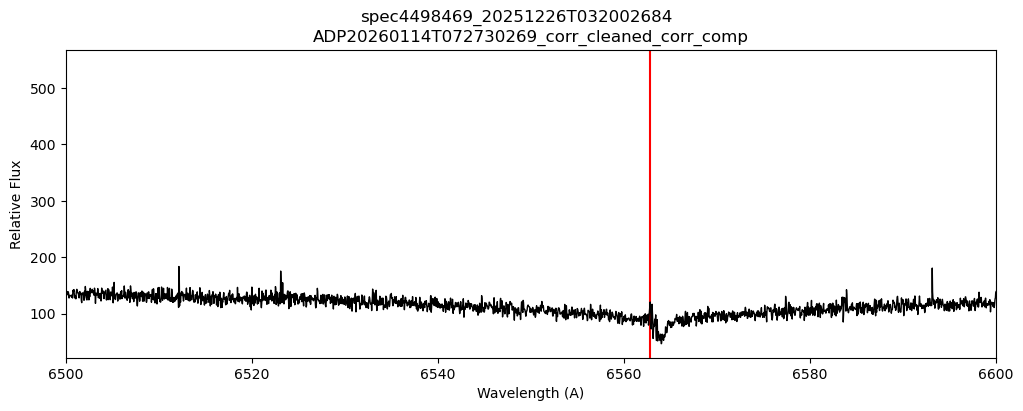

cleaned_corr_comp/wds/cleaned_corr_spec4498324_20251229T074925010


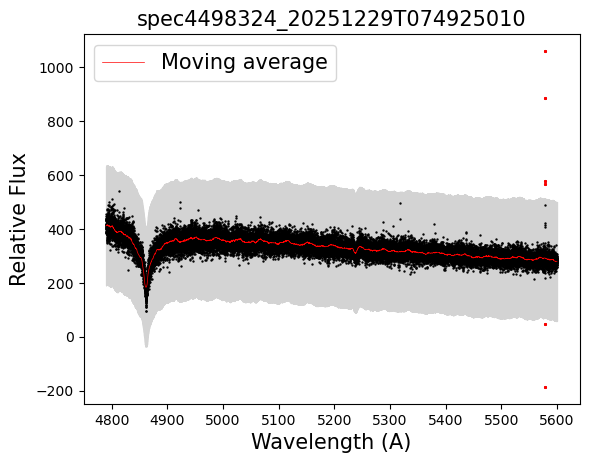

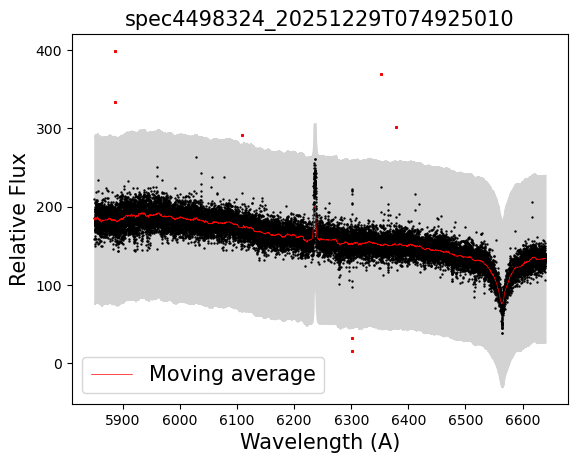

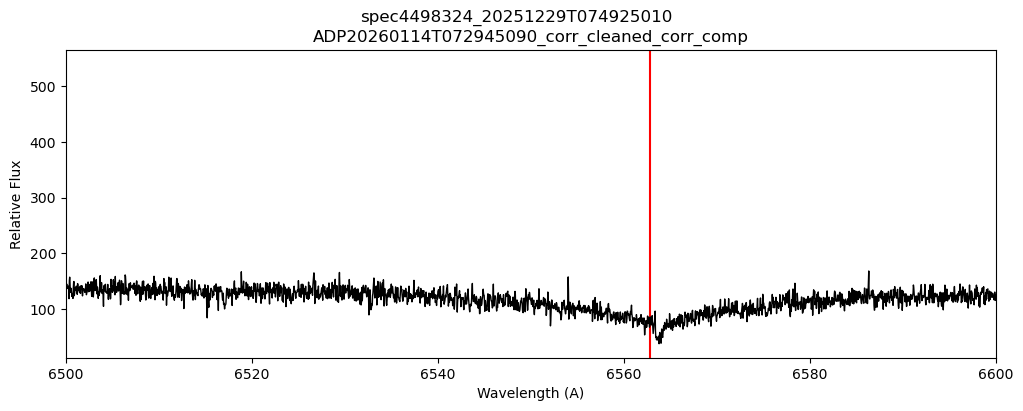

cleaned_corr_comp/wds/cleaned_corr_spec3119716_20211021T080906487


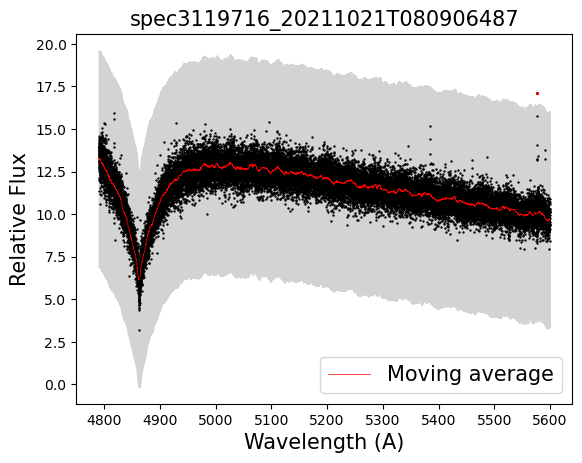

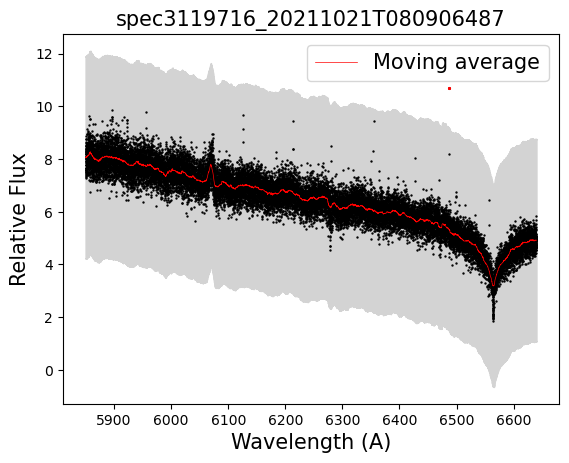

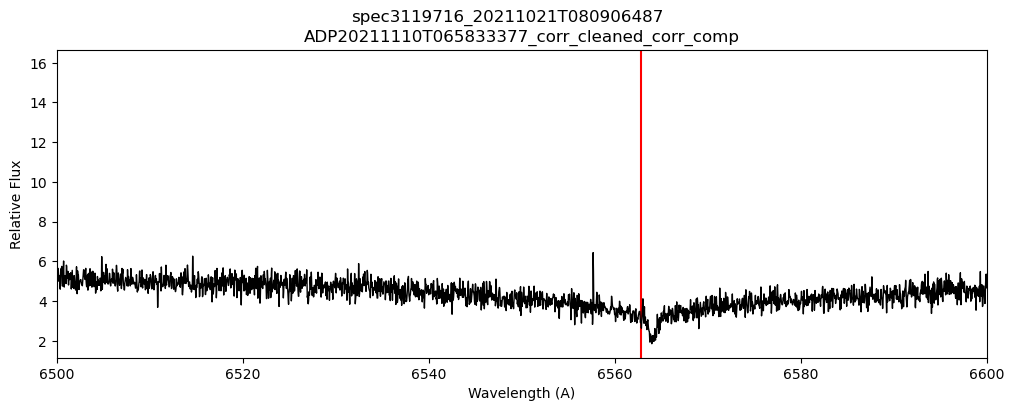

cleaned_corr_comp/wds/cleaned_corr_spec4498898_20251027T003052224


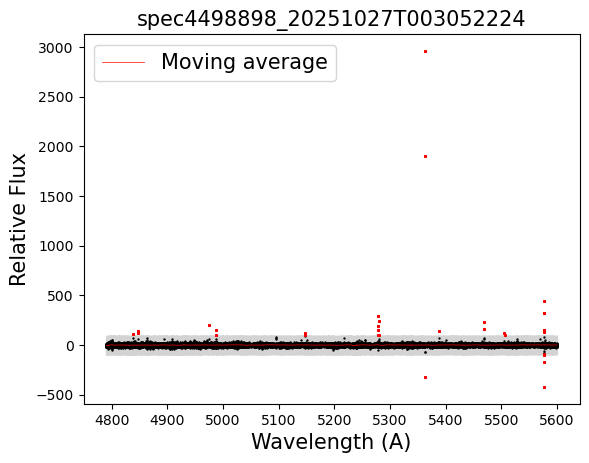

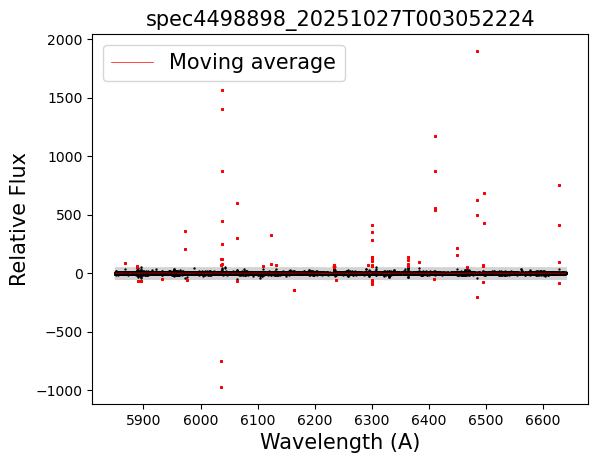

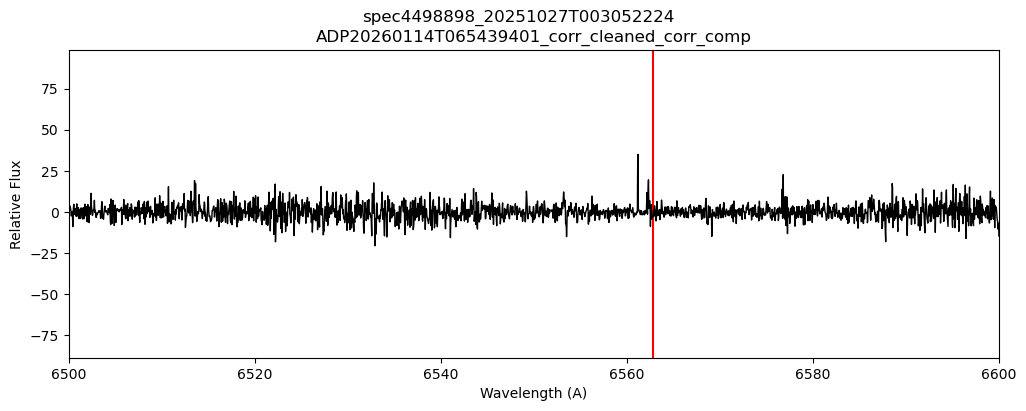

cleaned_corr_comp/wds/cleaned_corr_spec4498344_20260121T054555423


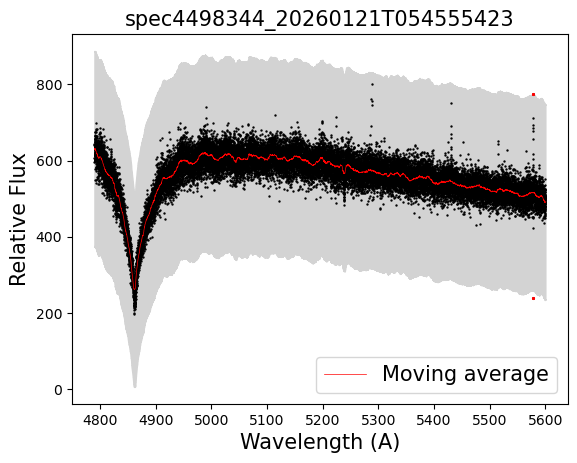

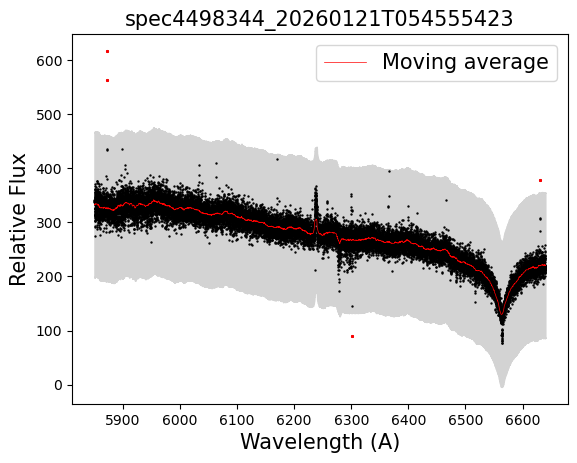

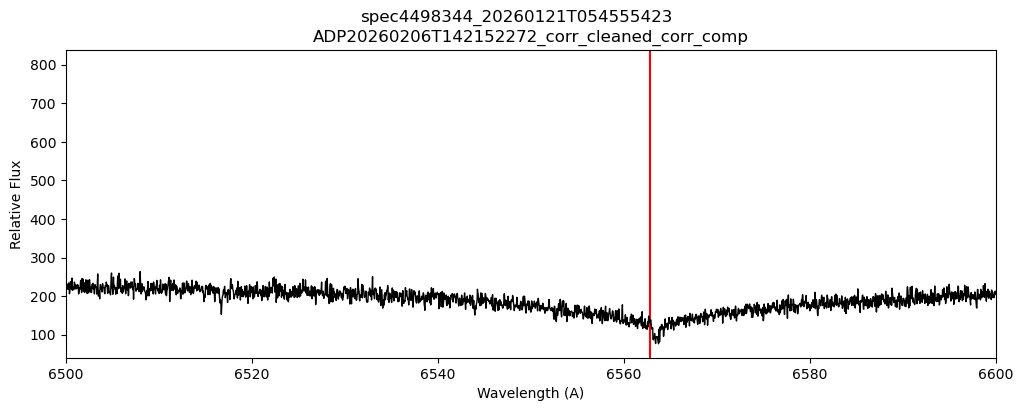

cleaned_corr_comp/wds/cleaned_corr_spec4498579_20260315T085226383


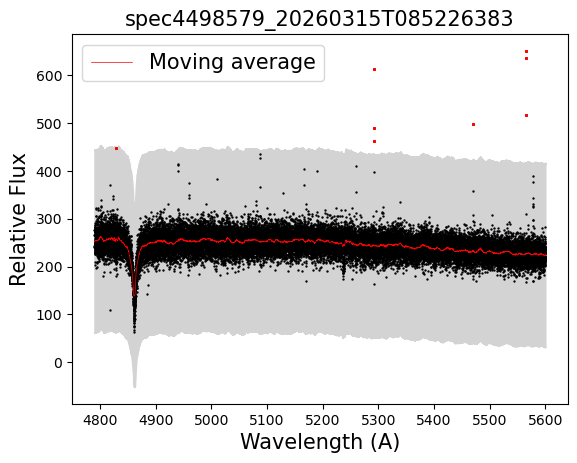

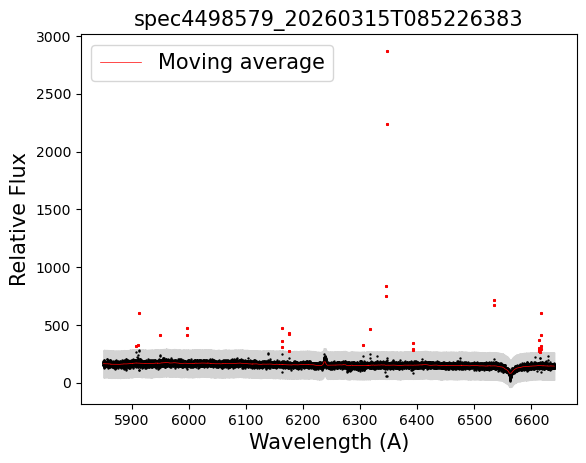

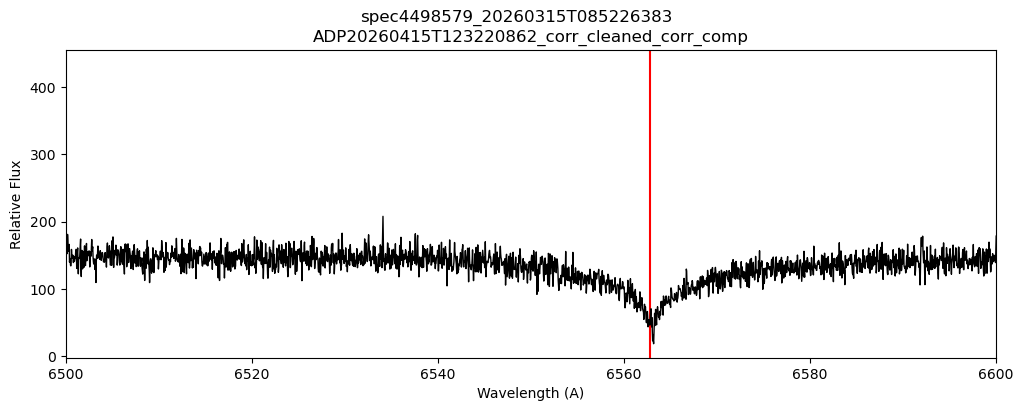

cleaned_corr_comp/wds/cleaned_corr_spec4498660_20251026T051345440


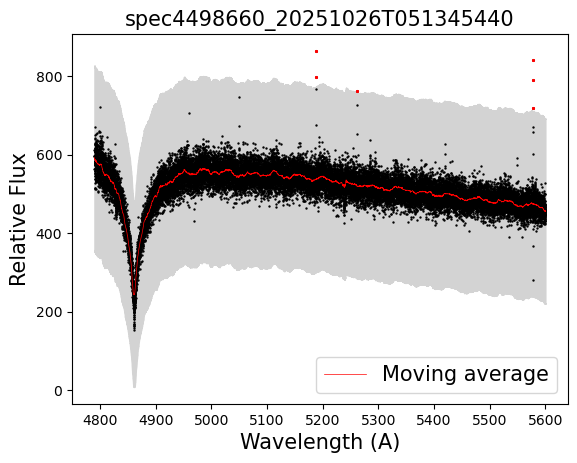

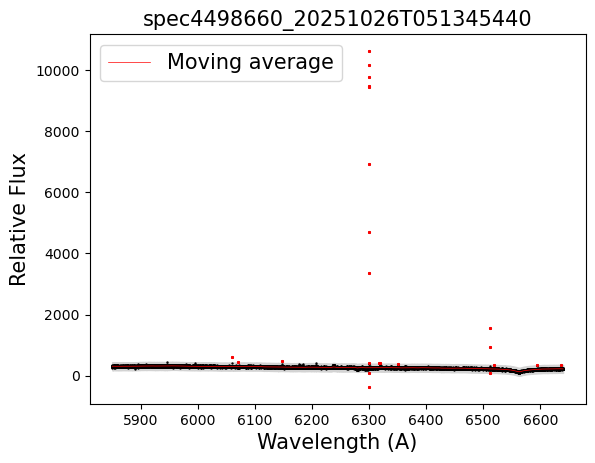

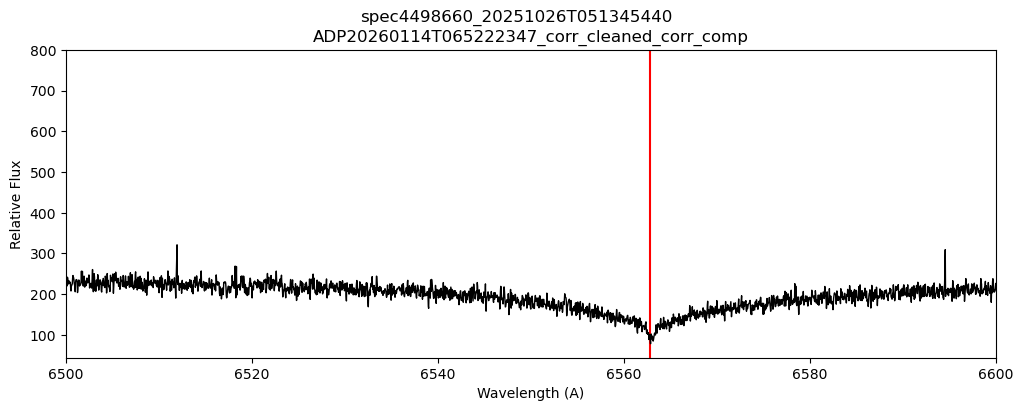

cleaned_corr_comp/wds/cleaned_corr_spec4498834_20251117T015352860


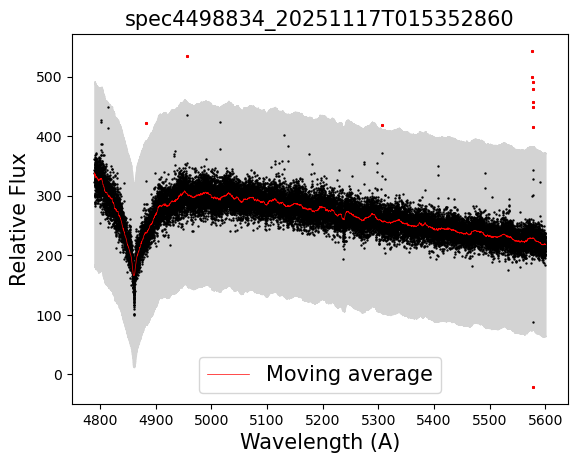

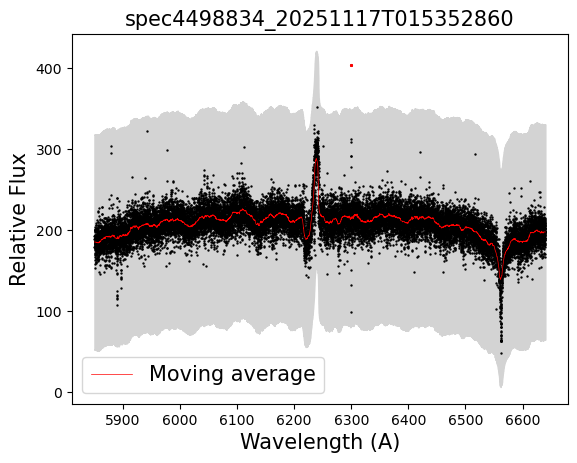

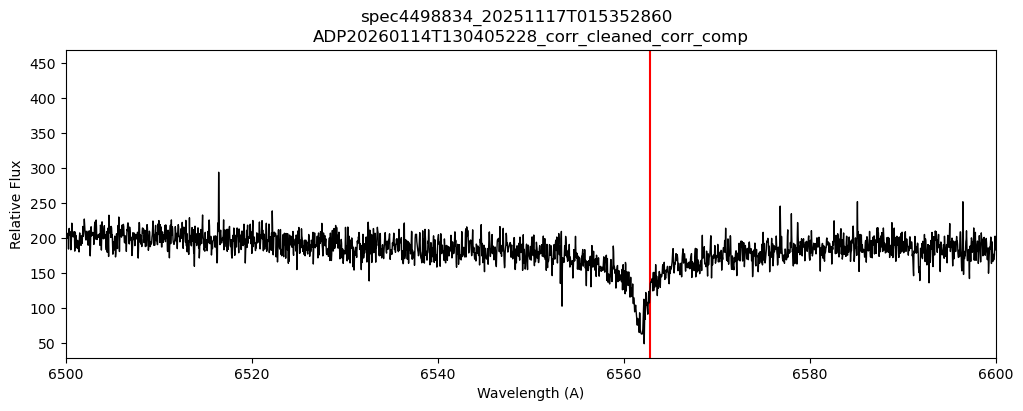

cleaned_corr_comp/wds/cleaned_corr_spec4498834_20251117T015352860


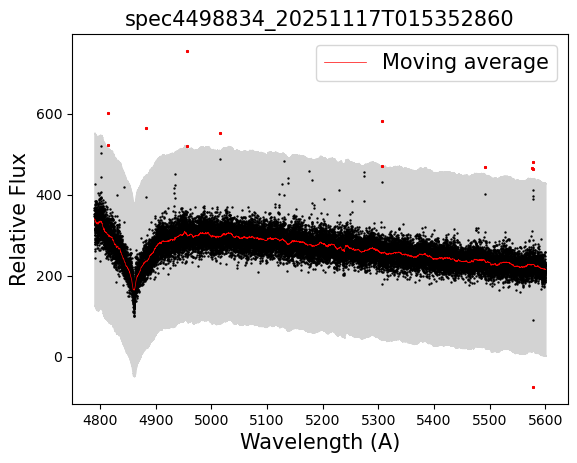

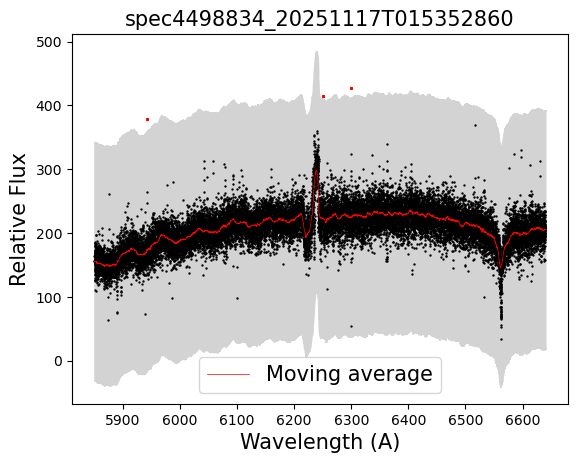

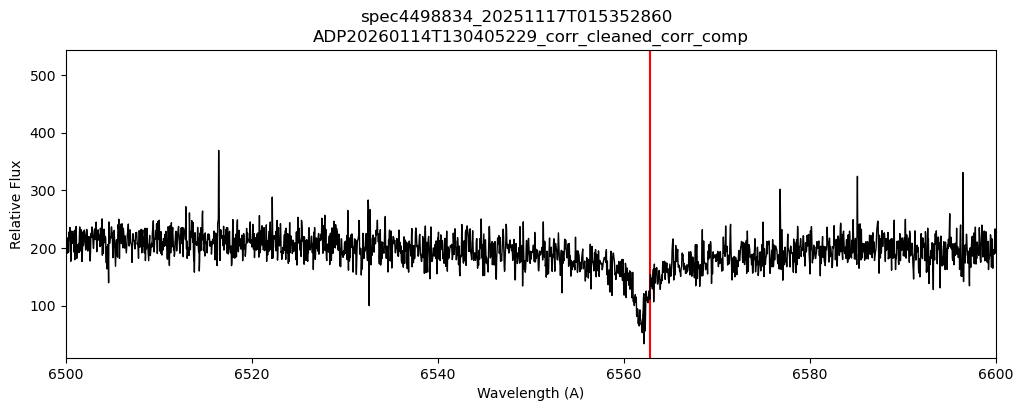

cleaned_corr_comp/wds/cleaned_corr_spec4498777_20260326T090523186


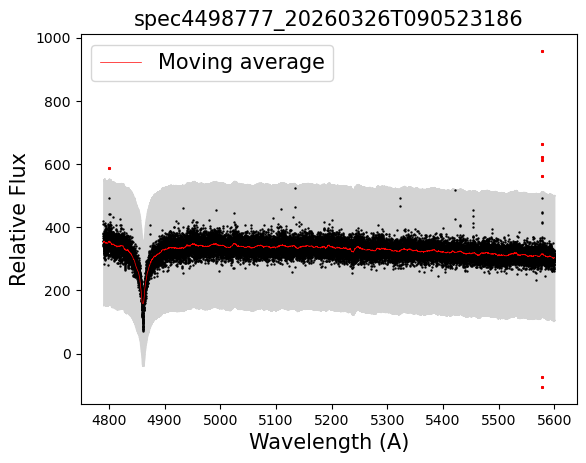

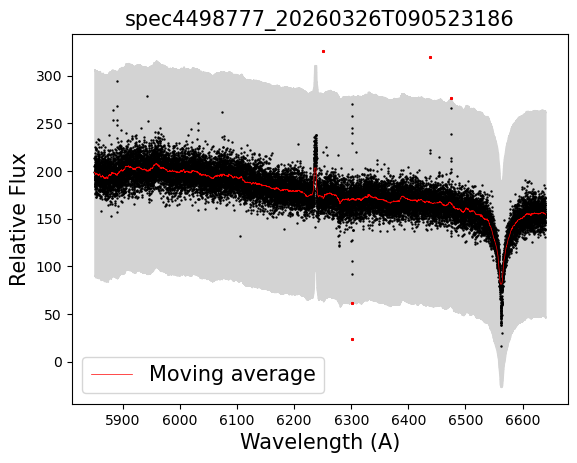

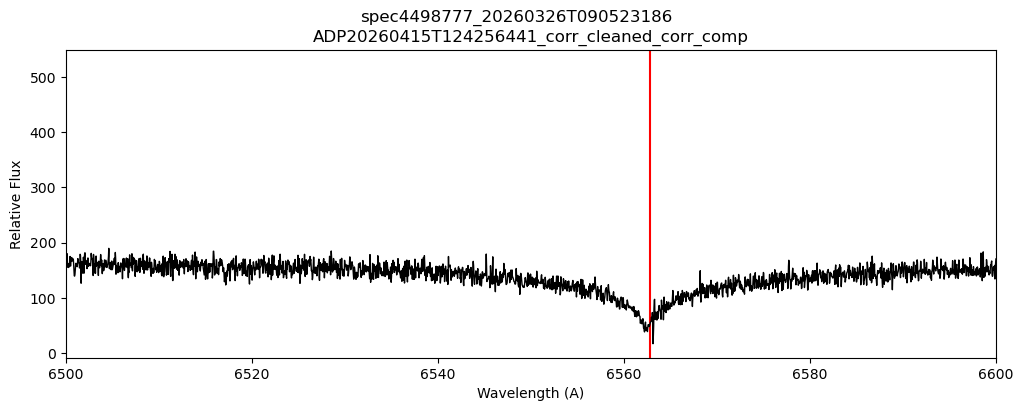

cleaned_corr_comp/wds/cleaned_corr_spec3119716_20211021T074457426


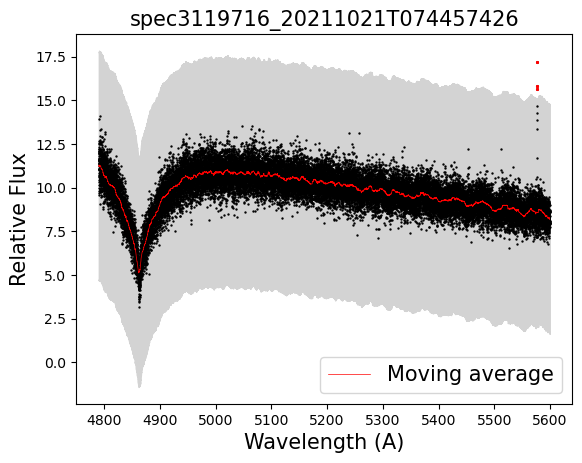

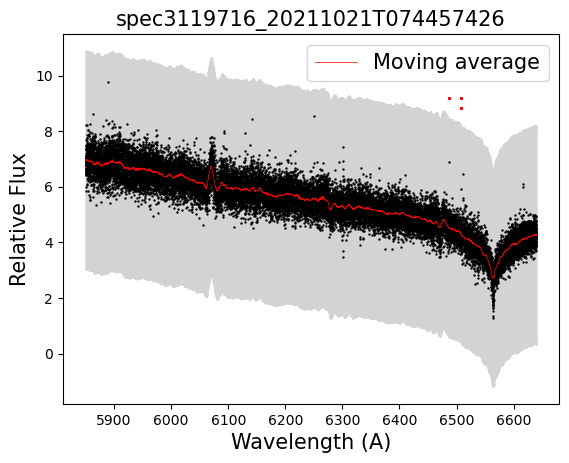

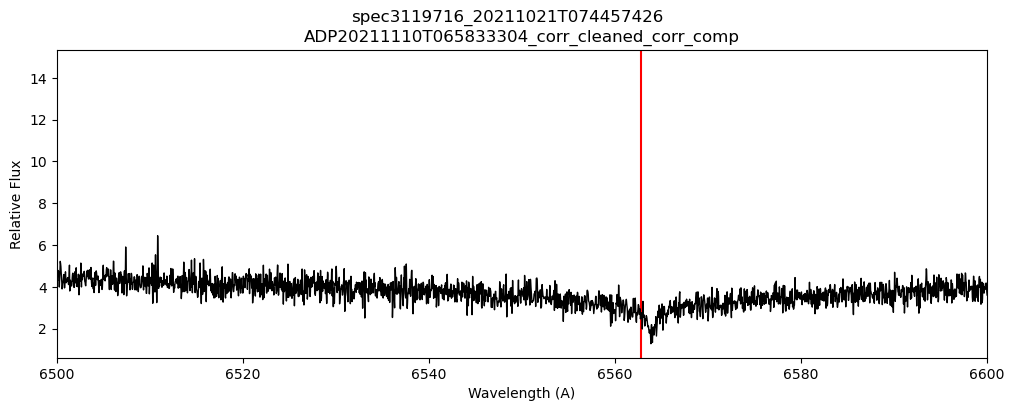

cleaned_corr_comp/wds/cleaned_corr_spec4498898_20251115T004618959


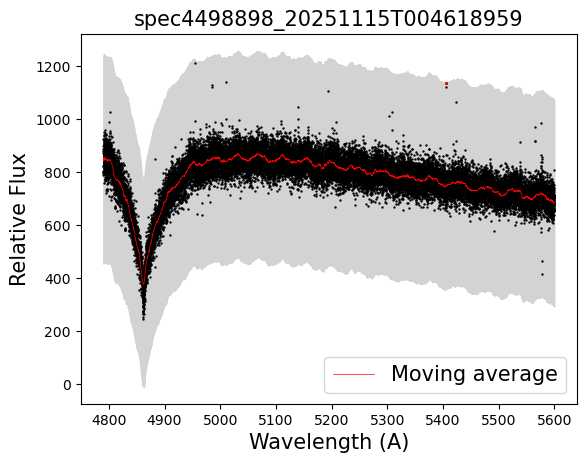

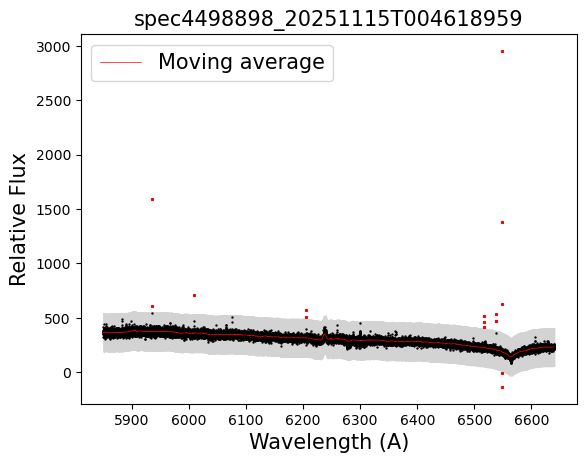

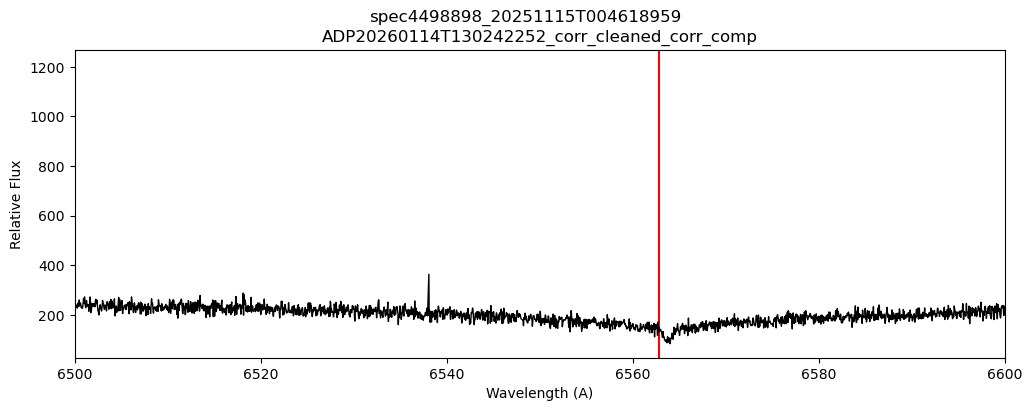

cleaned_corr_comp/wds/cleaned_corr_spec4498436_20251117T031453492


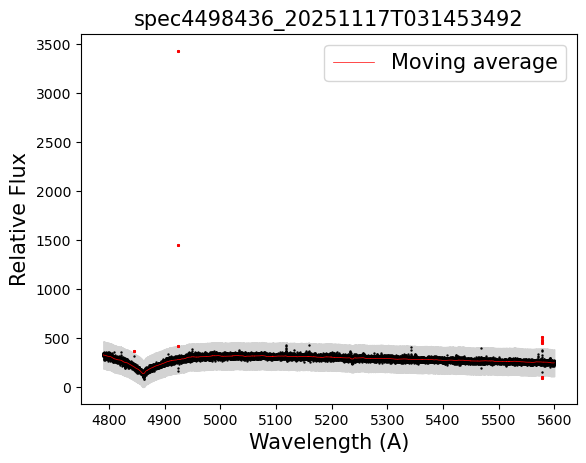

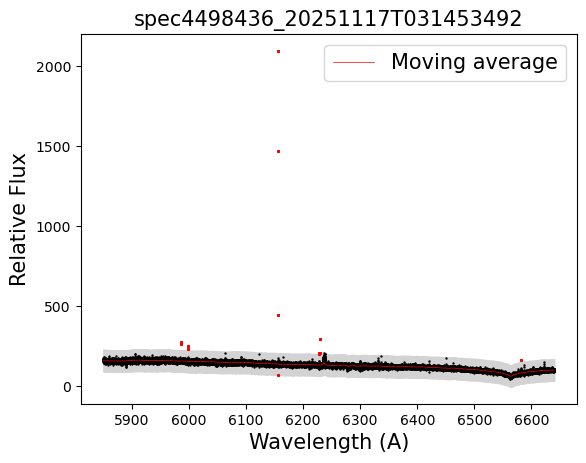

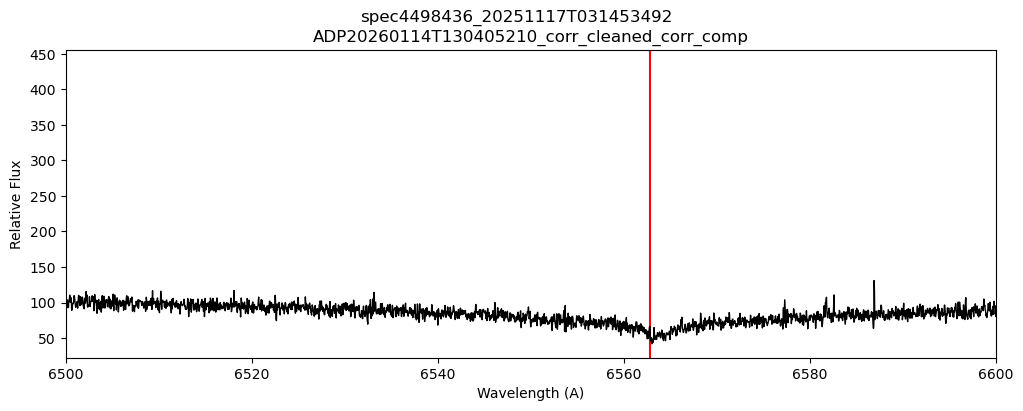

cleaned_corr_comp/wds/cleaned_corr_spec4498799_20260312T064143284


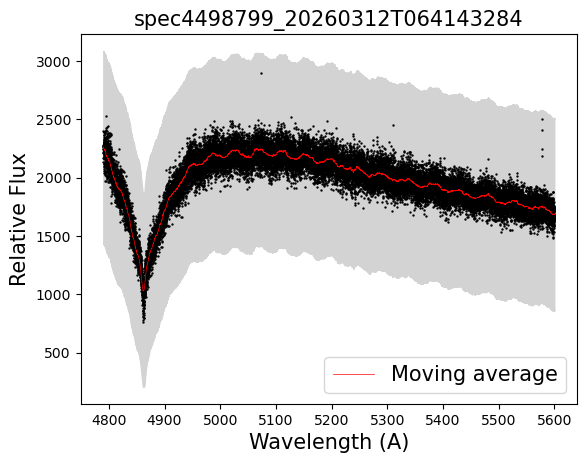

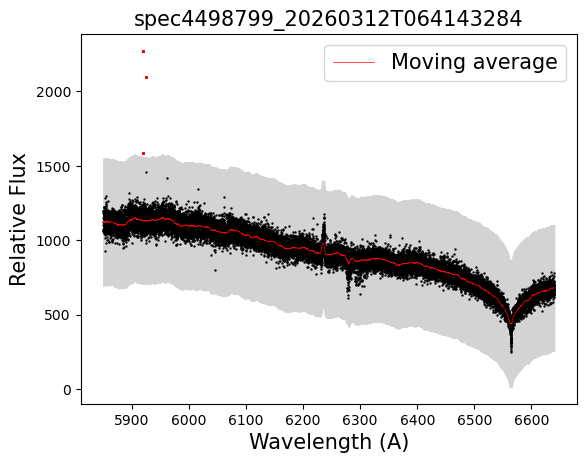

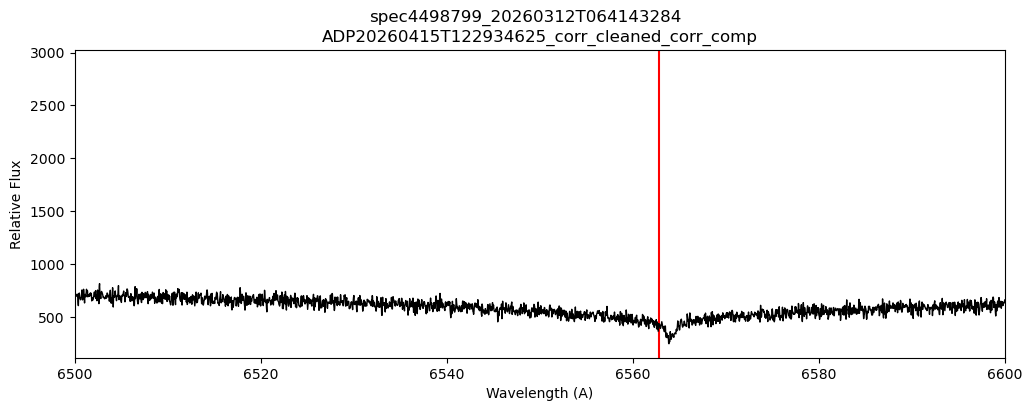

cleaned_corr_comp/wds/cleaned_corr_spec126412_20021231T010058267


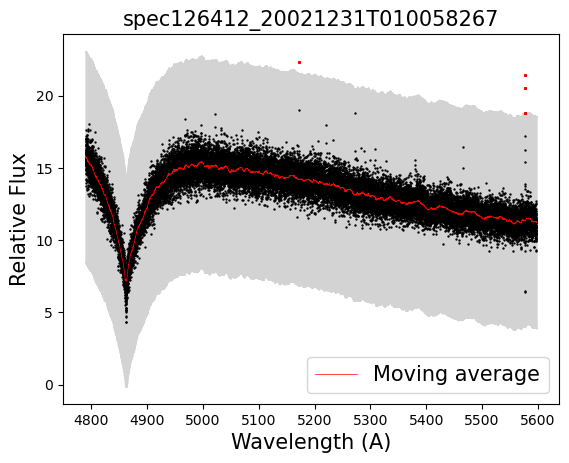

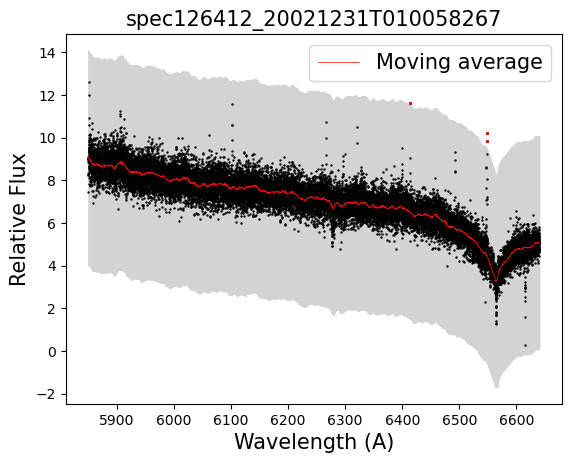

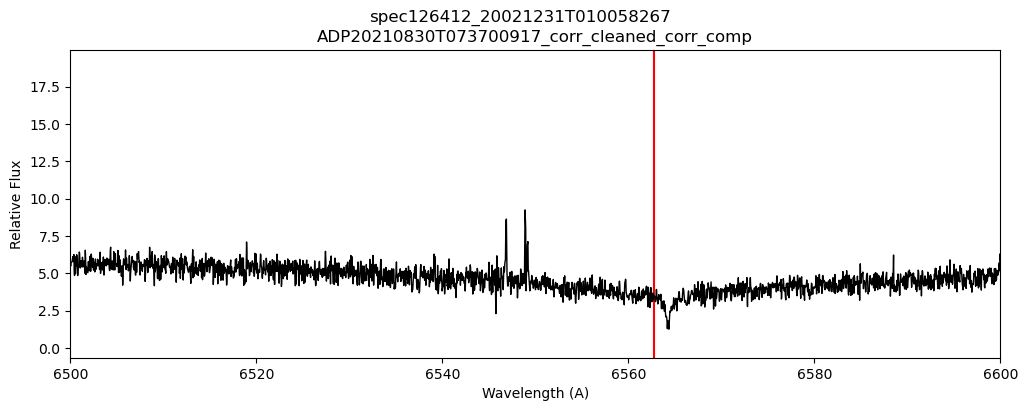

cleaned_corr_comp/wds/cleaned_corr_spec4498459_20251222T065500748


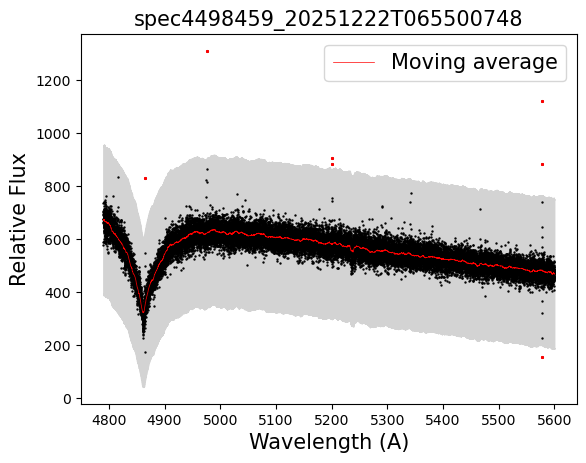

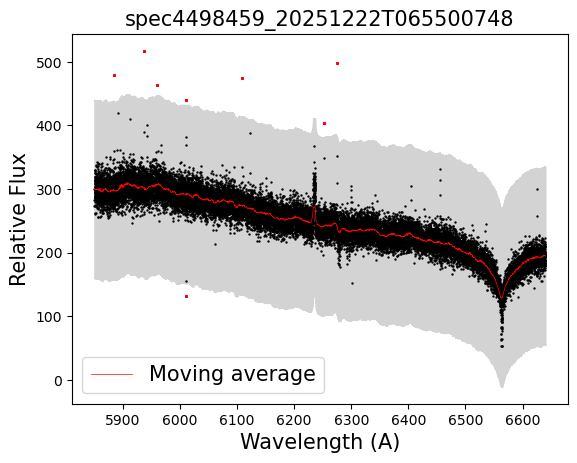

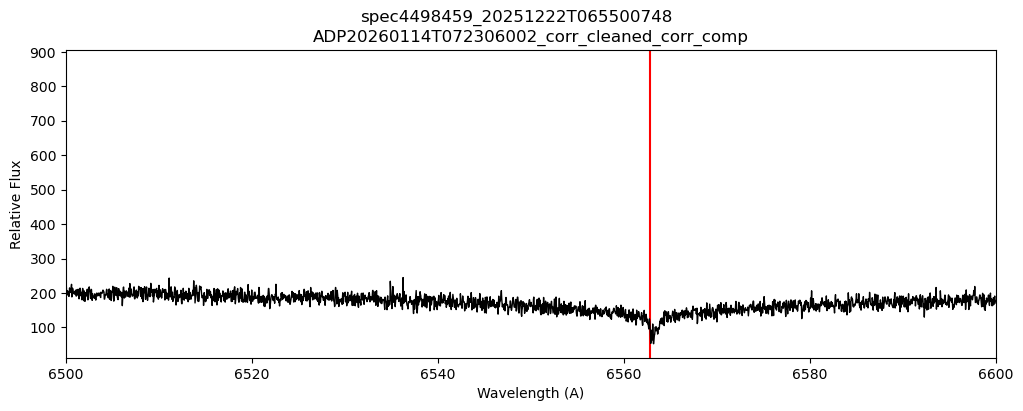

cleaned_corr_comp/wds/cleaned_corr_spec4498301_20251226T041344694


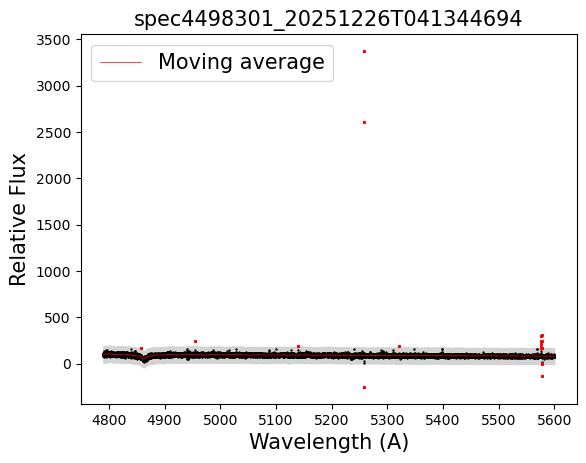

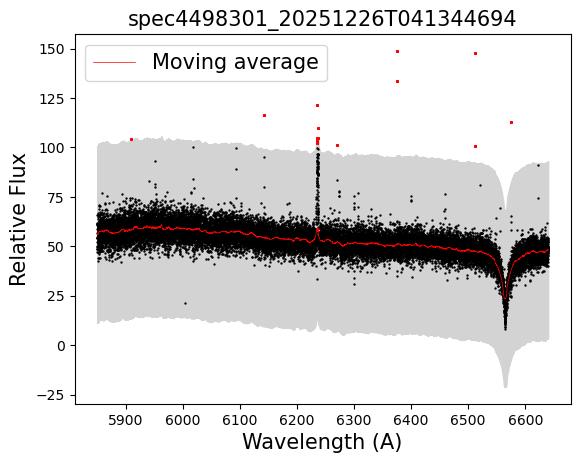

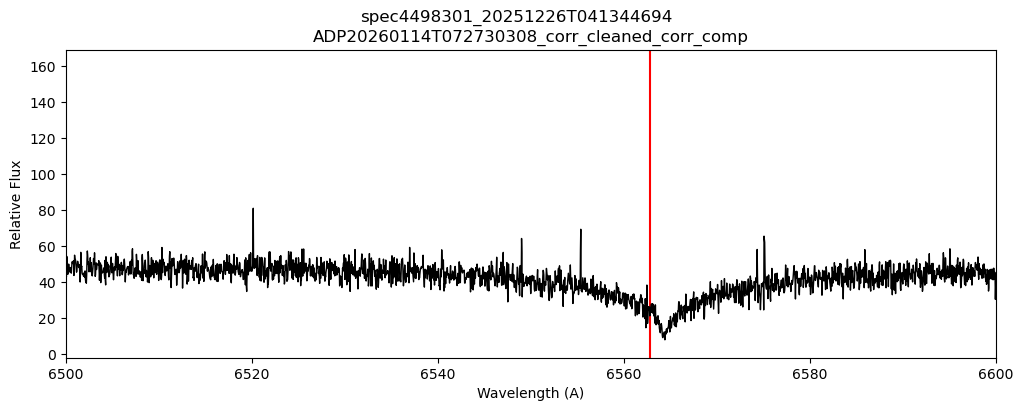

cleaned_corr_comp/wds/cleaned_corr_spec4498820_20251025T005108897


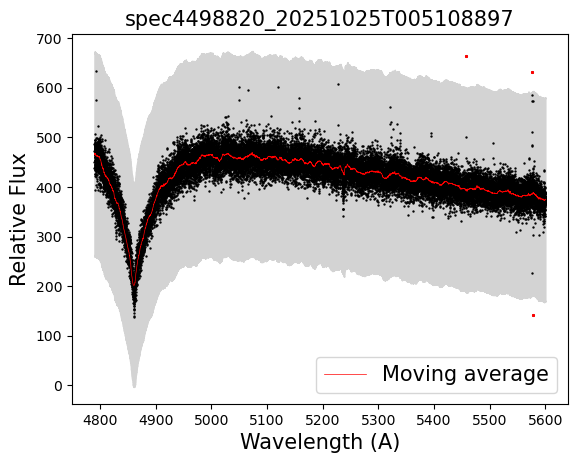

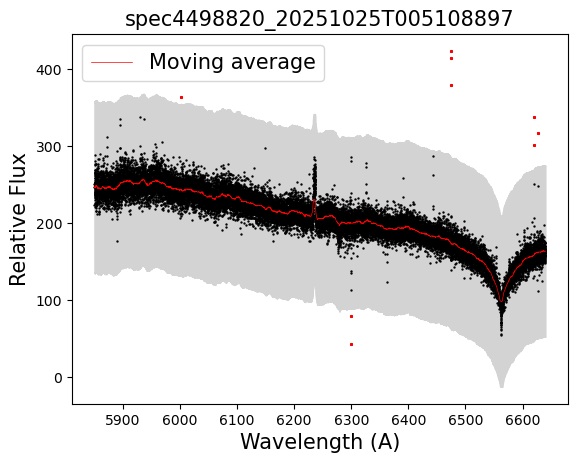

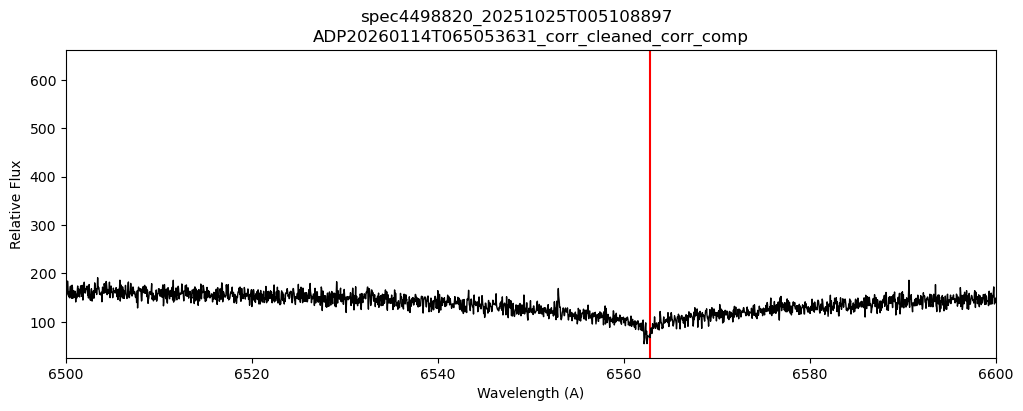

cleaned_corr_comp/wds/cleaned_corr_spec4498301_20251227T011118332


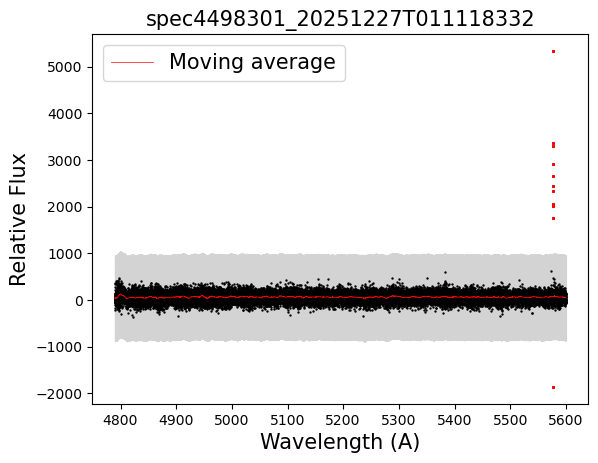

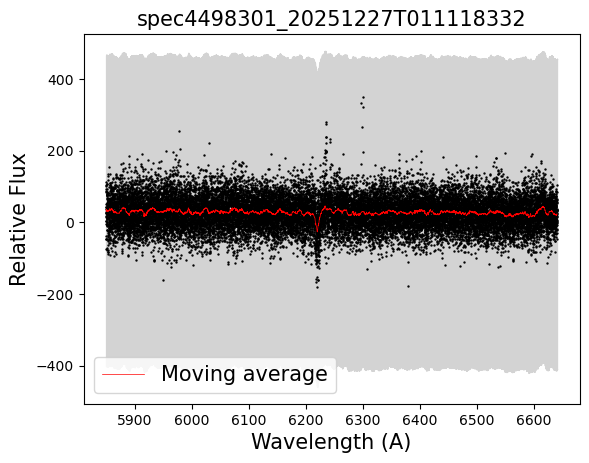

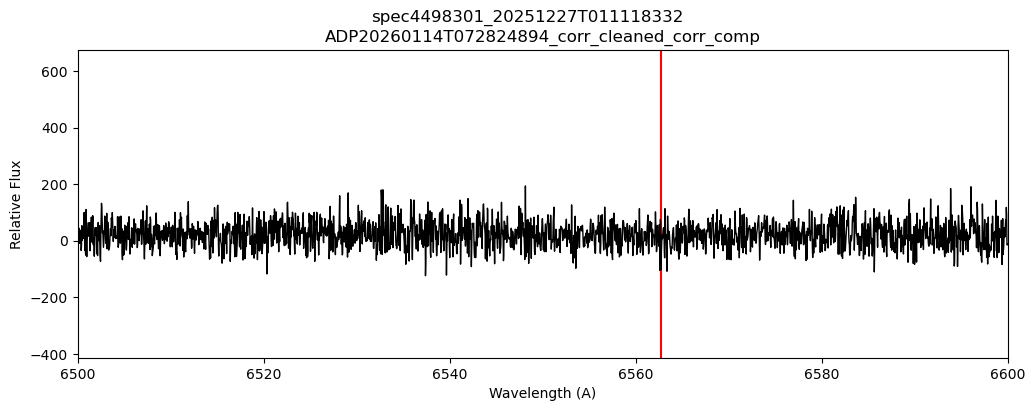

cleaned_corr_comp/wds/cleaned_corr_spec4498898_20251117T024853140


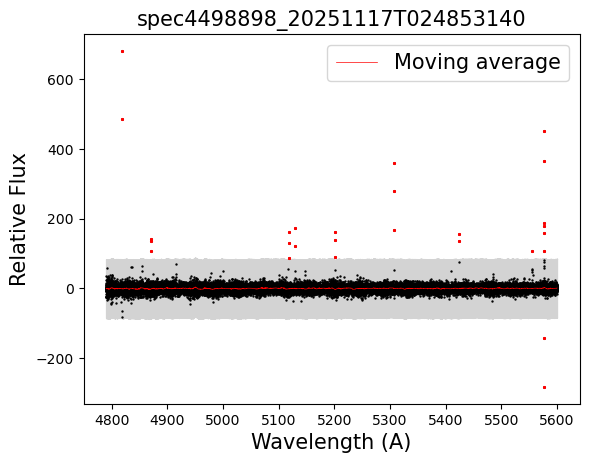

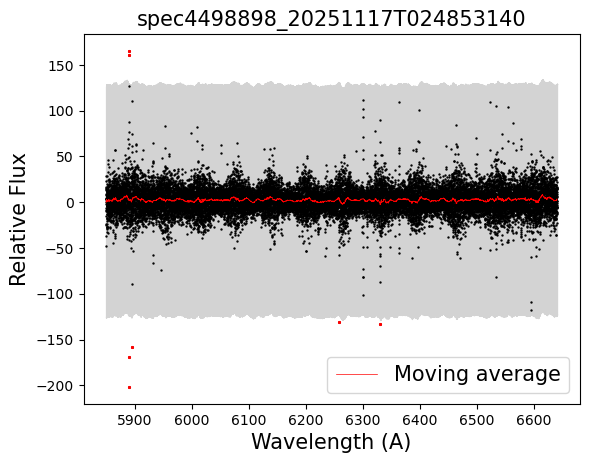

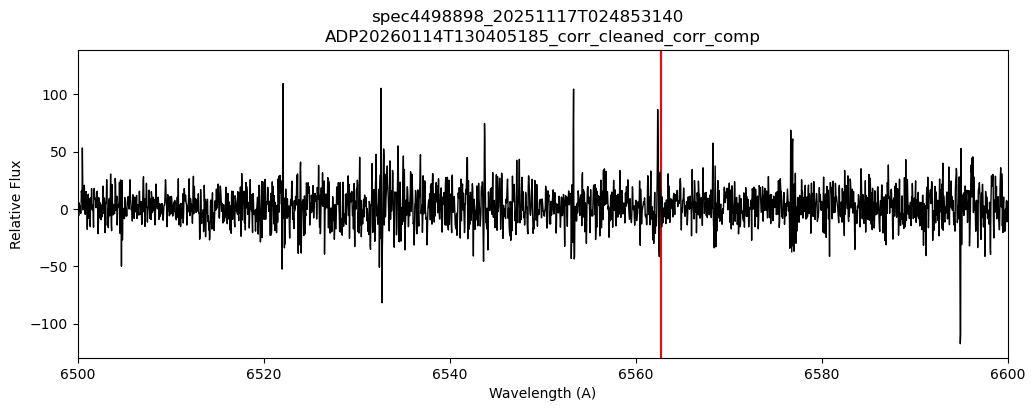

cleaned_corr_comp/wds/cleaned_corr_spec4498459_20251115T064926454


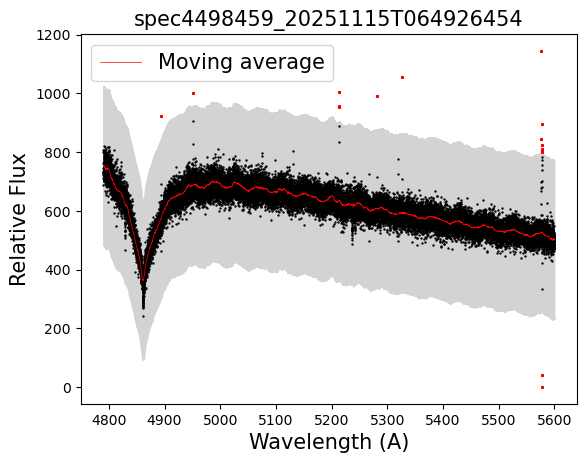

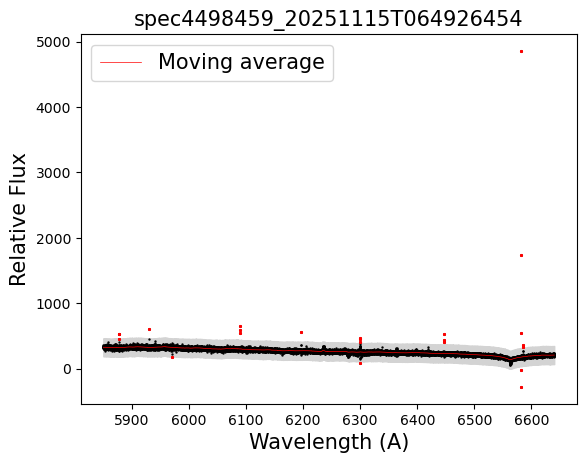

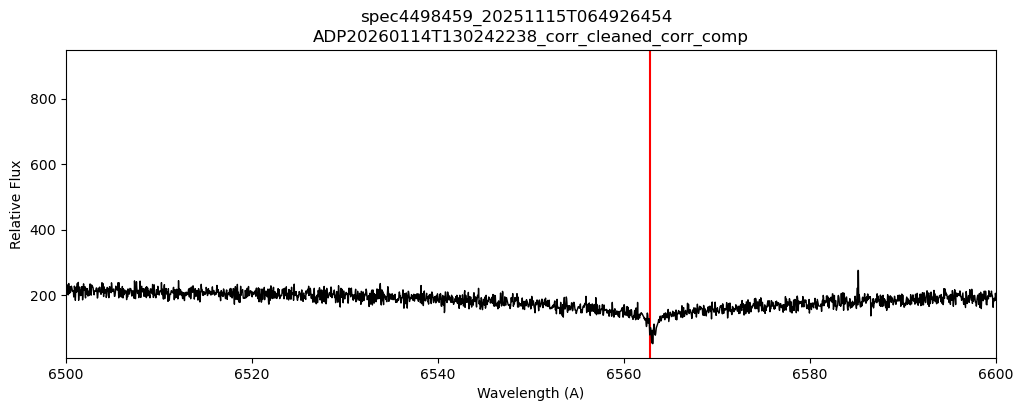

cleaned_corr_comp/wds/cleaned_corr_spec4498474_20251115T074711459


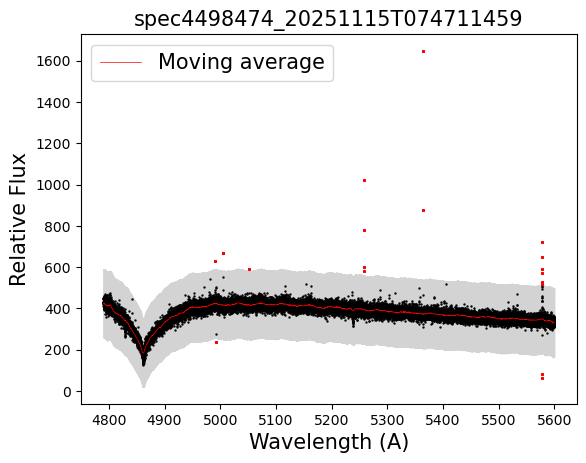

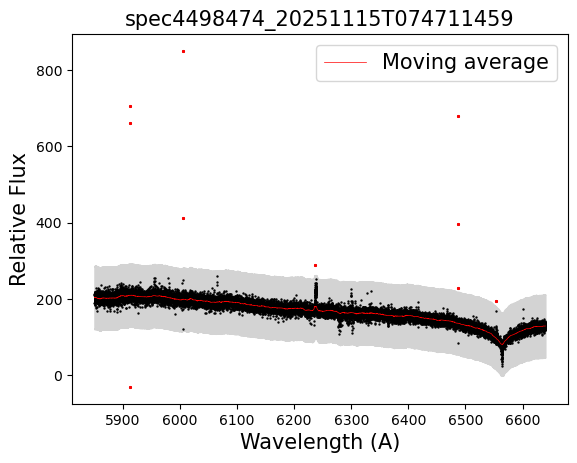

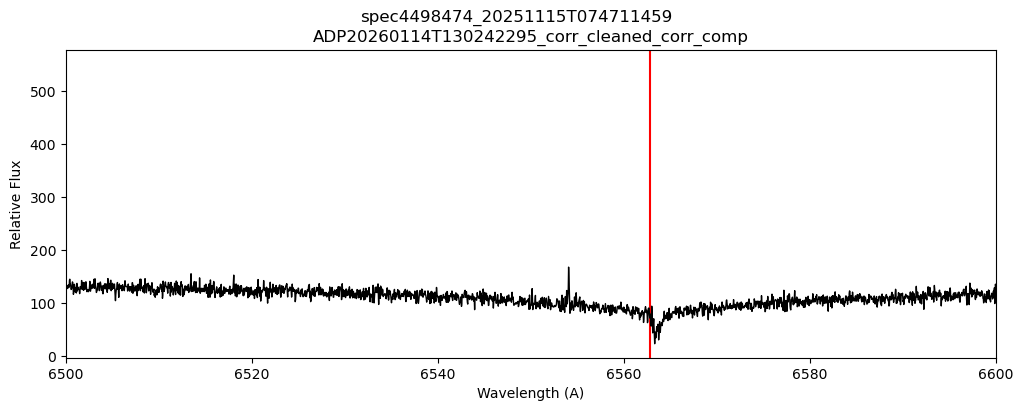

cleaned_corr_comp/wds/cleaned_corr_spec4498551_20251025T001253572


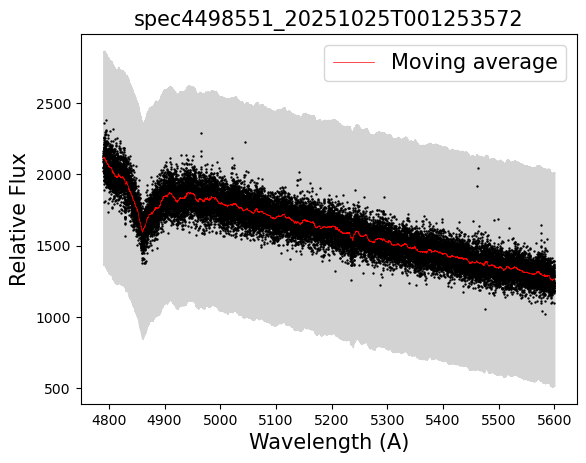

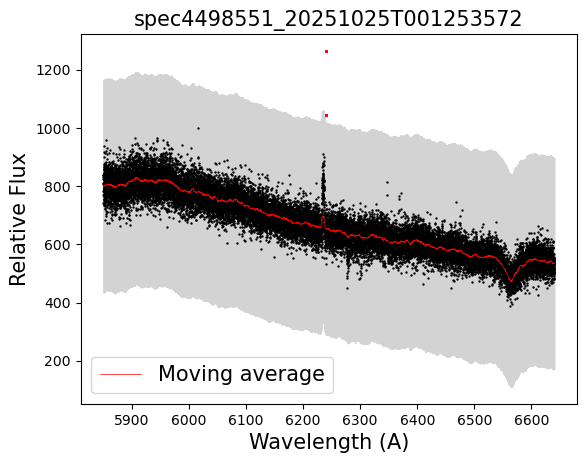

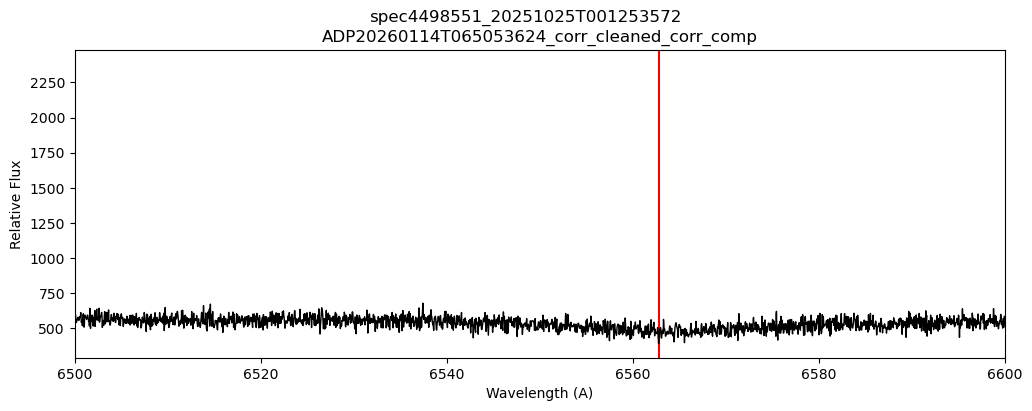

cleaned_corr_comp/wds/cleaned_corr_spec3110806_20220117T041533928


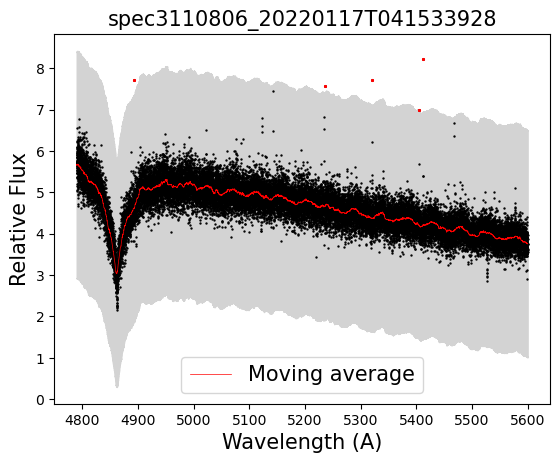

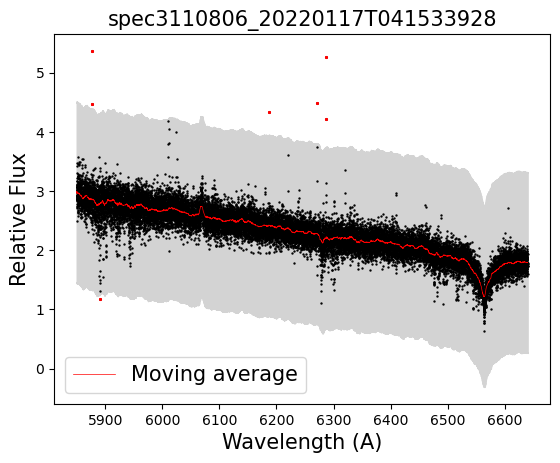

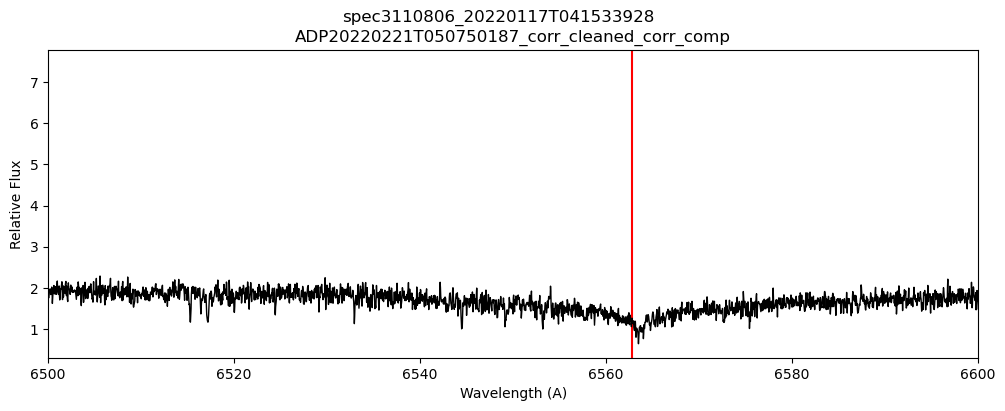

cleaned_corr_comp/wds/cleaned_corr_spec4498529_20260411T060427246


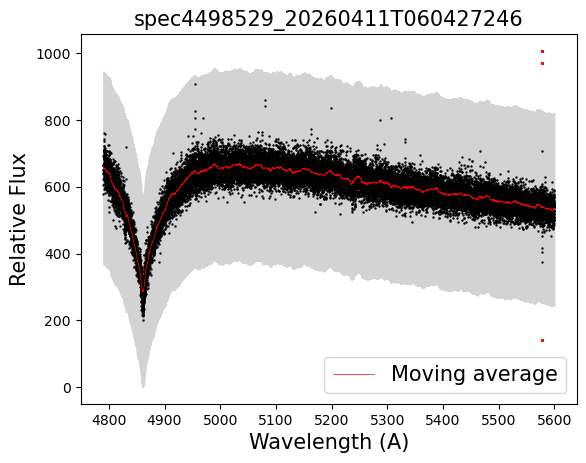

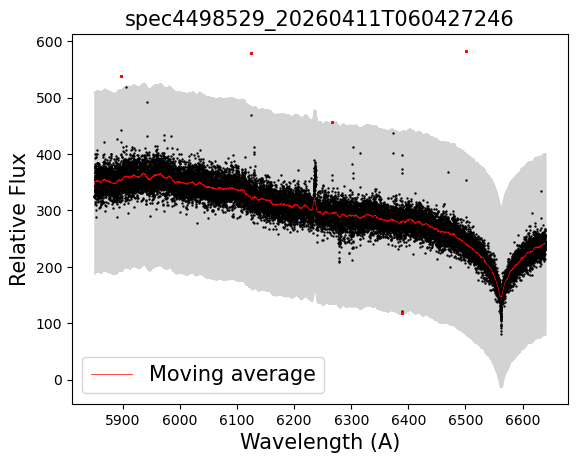

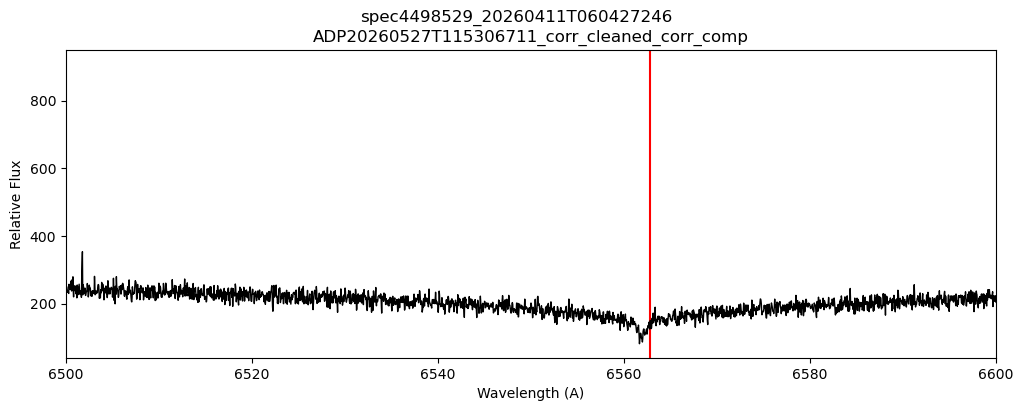

cleaned_corr_comp/wds/cleaned_corr_spec4498301_20260117T023704886


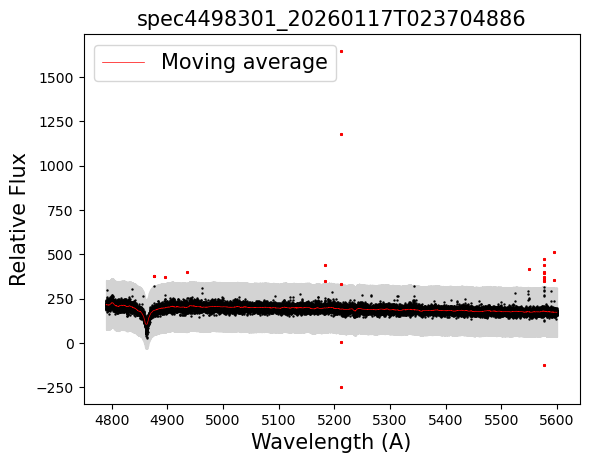

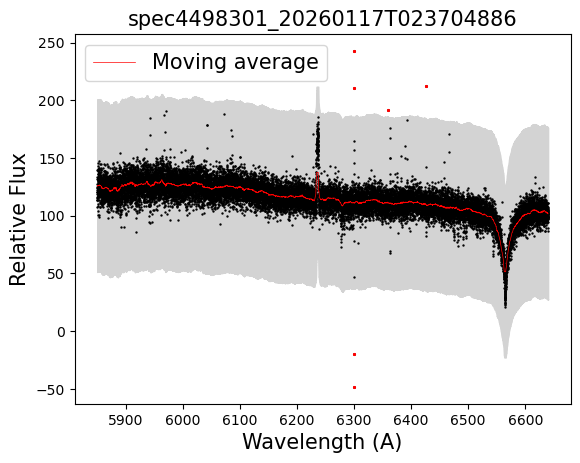

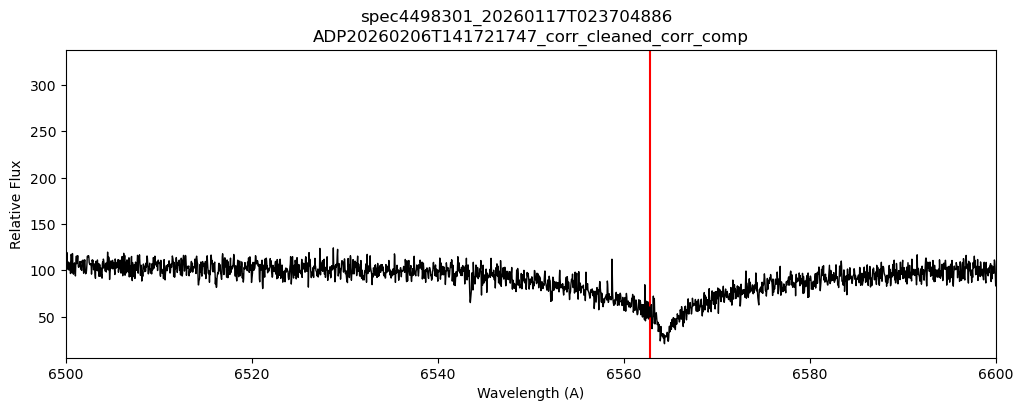

cleaned_corr_comp/wds/cleaned_corr_spec4498517_20260318T090835813


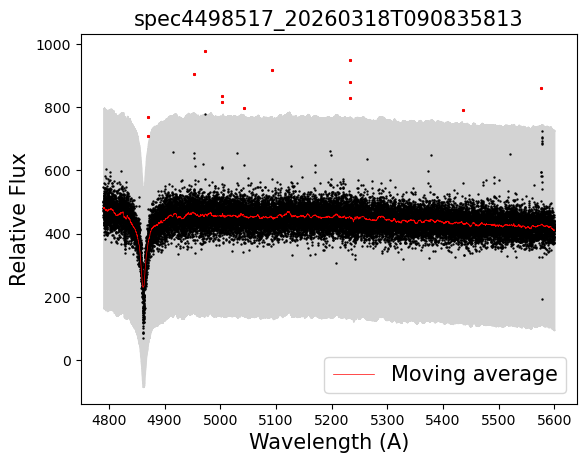

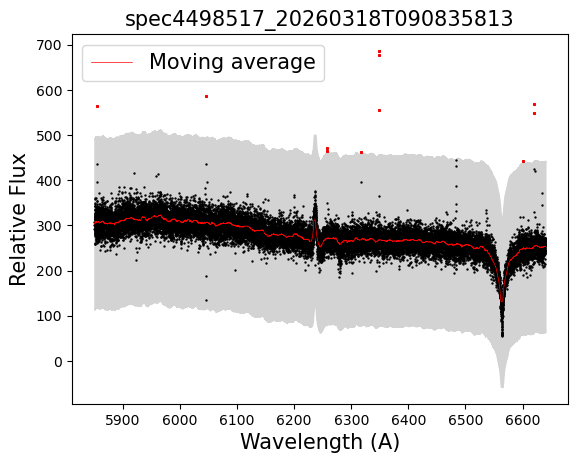

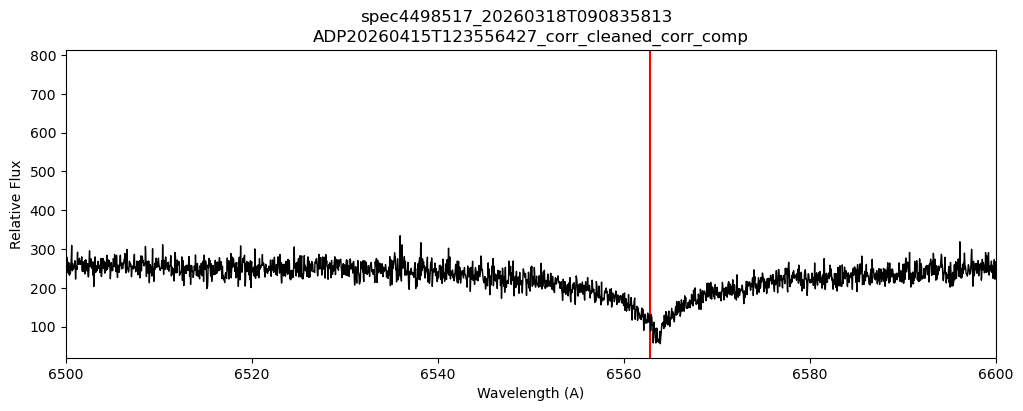

cleaned_corr_comp/wds/cleaned_corr_spec4498834_20251117T021717638


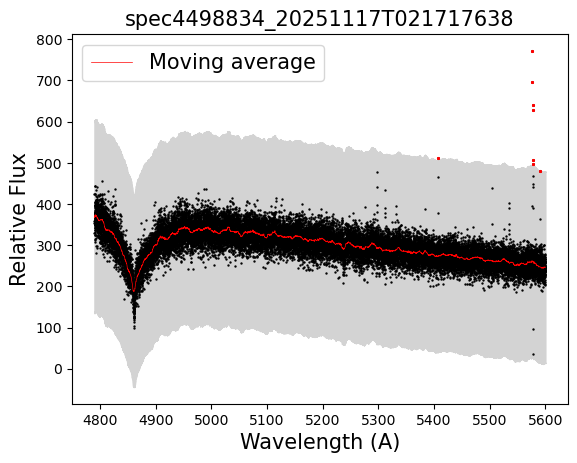

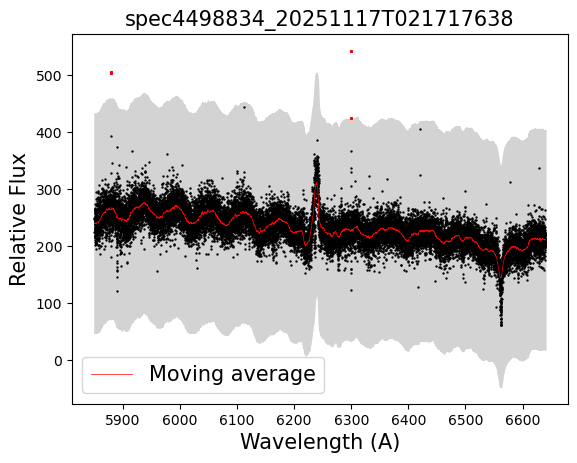

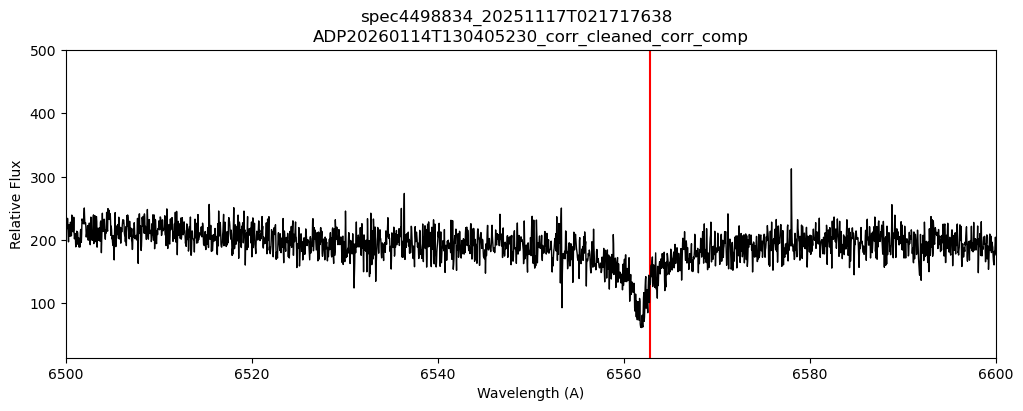

cleaned_corr_comp/wds/cleaned_corr_spec4498436_20251115T042515747


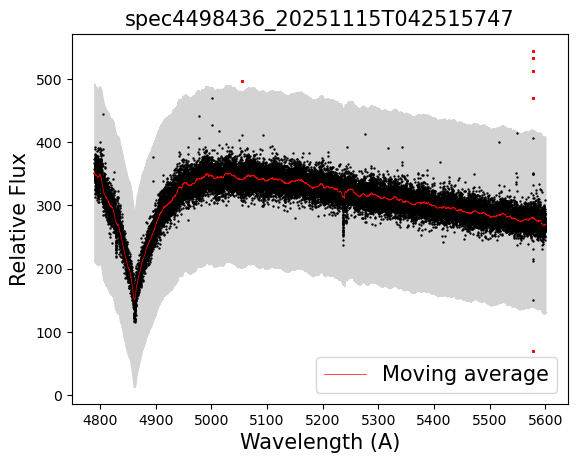

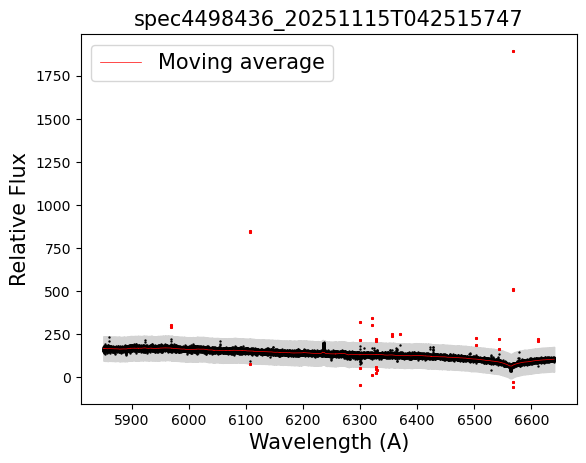

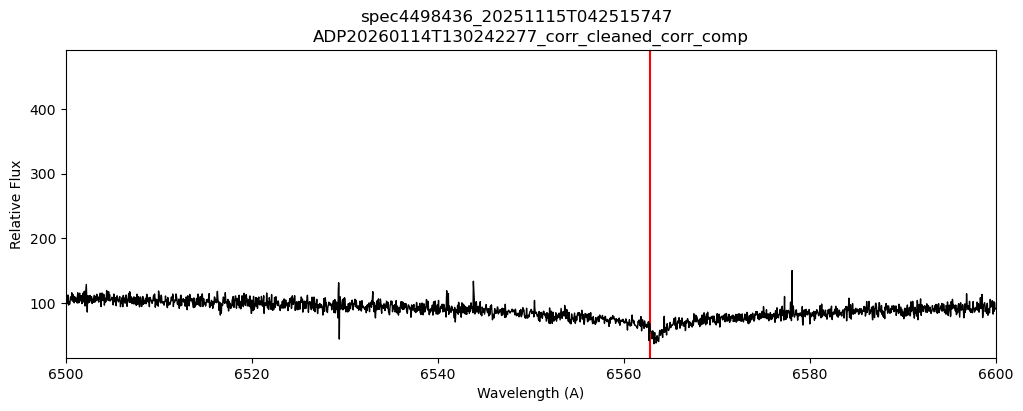

In [9]:
for espectro in esospec_corr_comp:

    file = pd.read_csv(espectro, sep=',', comment='#')

    nombre =  espectro.split('/')[8]
    adp = os.path.basename(espectro)
    adp = adp.replace('_completo.csv','_cleaned_corr_comp')
    
    path_clean = f'cleaned_corr_comp/wds/cleaned_corr_{nombre}'
    print(path_clean)
    Path(path_clean).mkdir(parents=True, exist_ok=True)

    
    observed_wave = file["wavelength"].values
    observed_flux = file["flux"].values

    mask2 = (observed_wave > 4790) & (observed_wave < g10)
    wave_tramo2 = observed_wave[mask2]
    flux_tramo2 = observed_flux[mask2]
    #eflux_tramo2 = observed_eflux[mask2]
    
    mask3 = (observed_wave > g11) & (observed_wave <= 6640)
    wave_tramo3 = observed_wave[mask3]
    flux_tramo3 = observed_flux[mask3]

    #eflux_tramo3 = observed_eflux[mask3]

    #if nombre.split('_')[0] == 'WD0126p101':
    #   plt.plot(observed_wave[mask3], observed_flux[mask3], c='green', lw=.1)
    #   plt.show()

    plot_bad = False
        
    s_wave_tramo2, s_flux_corrected_tramo2 = bad_pixels(nombre, wave_tramo2, flux_tramo2, window=201, std_cut=10, plot_bad = True)
    s_wave_tramo3, s_flux_corrected_tramo3 = bad_pixels(nombre, wave_tramo3, flux_tramo3, window=201, std_cut=10, plot_bad = True)
        
                
    wave_total = np.concatenate((s_wave_tramo2, s_wave_tramo3))
    flux_total = np.concatenate((s_flux_corrected_tramo2, s_flux_corrected_tramo3))
            
    with open(f"{path_clean}/cleaned_corr_{nombre}.csv", "w") as f_out:
        f_out.write("wave,flux\n")
        for w, f in zip(wave_total, flux_total):#, eflux_total):
            f_out.write(f"{w},{f}\n")

    #with open(f"/Users/mariajesusfloresmoraga/Desktop/IFMR_2/cleaned_p116/{nombre}", "w") as f_out:
    #     f_out.write("wave flux\n")
    #     for w, f in zip(wave_total, flux_total):#, eflux_total):
    #         f_out.write(f"{w} {f}\n")

    plt.figure(figsize=(12,4))
    plt.suptitle(f'{nombre}')
    plt.title(f'{adp}')
    plt.axvline(6562.79	, c='r')
    plt.xlim(6500,6600)
    plt.plot(wave_total, flux_total, c='k', lw=1)
    #plt.axvline(6562.79, c='r')
    #plt.xlim(6540,6580)
    plt.xlabel('Wavelength (A)')
    plt.ylabel('Relative Flux')
    plt.savefig(f'{path_clean}/cleaned_corr_{nombre}_Ha.pdf', dpi=100)
    plt.show()